In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestClassifier 

In [2]:
train = pd.read_csv('train-en.csv')
eval_en = pd.read_csv('eval-en.csv')


In [3]:
# Convert Date
train['Date'] = pd.to_datetime(train['Date'])
eval_en['Date']  = pd.to_datetime(eval_en['Date'])
print("Train shape:", train.shape)
print("Eval shape: ", eval_en.shape)
train.head()

Train shape: (52508, 19)
Eval shape:  (17668, 19)


,Date,wind_speed48M,wind_speed100M,wind_speed152M,wind_direction48M,wind_direction100M,wind_direction152M,wind_speed_100MP10,wind_speed_100MP20,wind_speed_100MP30,wind_speed_100MP40,wind_speed_100MP50,wind_speed_100MP60,wind_speed_100MP70,wind_speed_100MP80,wind_speed_100MP90,Interpolated,available_capacity,Output
0,2016-01-01 00:00:00,8.490,10.7700,12.690,188.00,190.0,194.00,9.0700,9.630,10.060,10.43,10.78,11.0500,11.5400,11.940,12.4200,0,122400,79168
1,2016-01-01 00:15:00,8.395,10.6175,12.475,190.75,193.0,196.75,9.0425,9.555,9.955,10.31,10.63,10.9275,11.3875,11.815,12.3125,1,122400,75124
2,2016-01-01 00:30:00,8.300,10.4650,12.260,193.50,196.0,199.50,9.0150,9.480,9.850,10.19,10.48,10.8050,11.2350,11.690,12.2050,1,122400,76072
3,2016-01-01 00:45:00,8.205,10.3125,12.045,196.25,199.0,202.25,8.9875,9.405,9.745,10.07,10.33,10.6825,11.0825,11.565,12.0975,1,122400,67964
4,2016-01-01 01:00:00,8.110,10.1600,11.830,199.00,202.0,205.00,8.9600,9.330,9.640,9.95,10.18,10.5600,10.9300,11.440,11.9900,0,122400,69988


                             Date  wind_speed48M  wind_speed100M  \
count                       52508   52508.000000    52508.000000   
mean   2016-09-30 11:56:55.879485       5.626846        6.834925   
min           2016-01-01 00:00:00       0.550000        0.580000   
25%           2016-05-16 18:41:15       3.925000        4.850000   
50%           2016-09-30 12:22:30       5.330000        6.650000   
75%           2017-02-14 05:03:45       6.965000        8.555000   
max           2017-06-30 23:45:00      18.870000       21.690000   
std                           NaN       2.466787        2.883092   

       wind_speed152M  wind_direction48M  wind_direction100M  \
count    52508.000000       52508.000000        52508.000000   
mean         7.583339         189.824055          191.399815   
min          0.570000           0.000000            0.000000   
25%          5.225000         119.000000          119.500000   
50%          7.395000         207.000000          209.250000   
75%

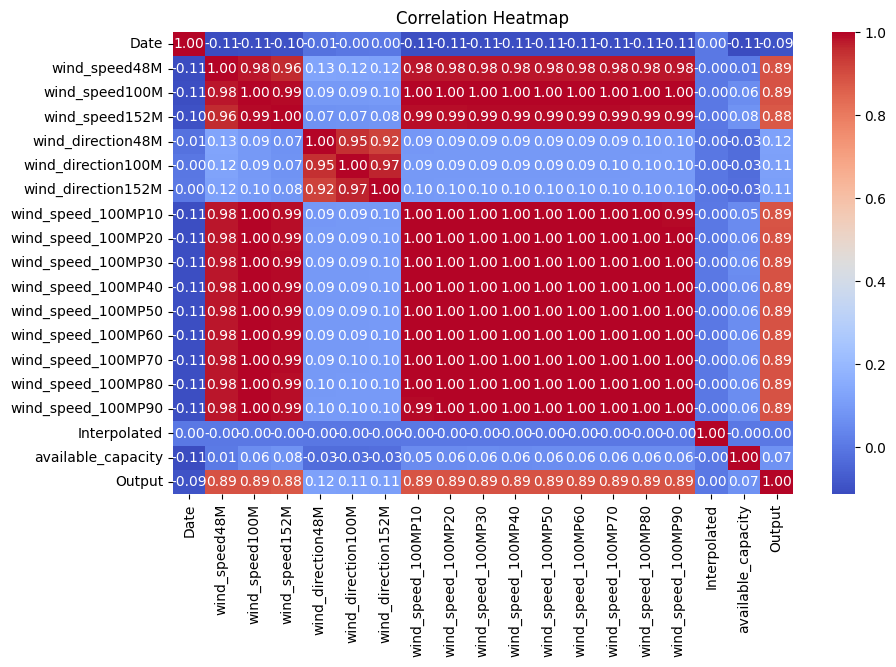

In [4]:
#Basic EDA
print(train.describe())
plt.figure(figsize=(10, 6))
sns.heatmap(train.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

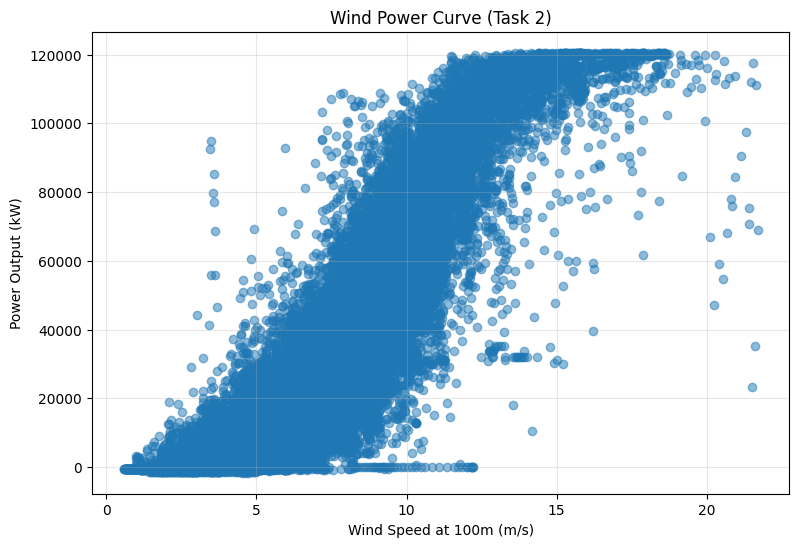

In [6]:
#power curve
plt.figure(figsize=(9,6))
plt.scatter(train['wind_speed100M'], train['Output'], alpha=0.5)
plt.xlabel('Wind Speed at 100m (m/s)')
plt.ylabel('Power Output (kW)')
plt.title('Wind Power Curve (Task 2)')
plt.grid(True, alpha=0.3)
plt.show()


In [8]:
#Feature Engineering (used for both regression and classification)
def engineer_features(df):
    data = df.copy()

    data = data.rename(columns=
                      {'wind_speed_100MP10': 'wind_speed_100MP10',
                       'wind_speed_100MP90': 'wind_speed_100MP90'})
    
    # Wind vector components at 100m (best height)
    data['u_100'] = data['wind_speed100M'] * np.cos(np.deg2rad(data['wind_direction100M']))
    data['v_100'] = data['wind_speed100M'] * np.sin(np.deg2rad(data['wind_direction100M']))
    
    # Physics features
    data['wind_shear'] = data['wind_speed152M'] - data['wind_speed48M']
    data['turbulence_intensity'] = (data['wind_speed_100MP90'] - data['wind_speed_100MP10']) / \
                                   data['wind_speed100M'].replace(0, np.nan)
    
    # Time features
    data['hour'] = data['Date'].dt.hour
    data['dayofweek'] = data['Date'].dt.dayofweek
    data['month'] = data['Date'].dt.month
    
    return data

df_train = engineer_features(train)
df_eval  = engineer_features(eval_en)

print("Feature engineering done.")

Feature engineering done.


In [10]:
# Cell 5: Regression with XGBoost (much stronger than LinearRegression)
import xgboost as xgb
from sklearn.metrics import mean_absolute_error
feature_cols = ['wind_speed48M', 'wind_speed100M', 'wind_speed152M',
                'u_100', 'v_100', 'wind_shear', 'turbulence_intensity',
                'hour', 'available_capacity']

X_train = df_train[feature_cols]
y_train = df_train['Output']

X_eval = df_eval[feature_cols]
y_eval = df_eval['Output']

model = xgb.XGBRegressor(
    n_estimators=800,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.8,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_eval)

# Evaluation
r2 = r2_score(y_eval, predictions)
mae = mean_absolute_error(y_eval, predictions)
rmse = np.sqrt(mean_squared_error(y_eval, predictions))

print("=== Regression Results (Task 4) ===")
print(f"R²:   {r2:.4f}")
print(f"MAE:  {mae:,.0f} kW")
print(f"RMSE: {rmse:,.0f} kW")

=== Regression Results (Task 4) ===
R²:   0.7863
MAE:  10,095 kW
RMSE: 15,062 kW


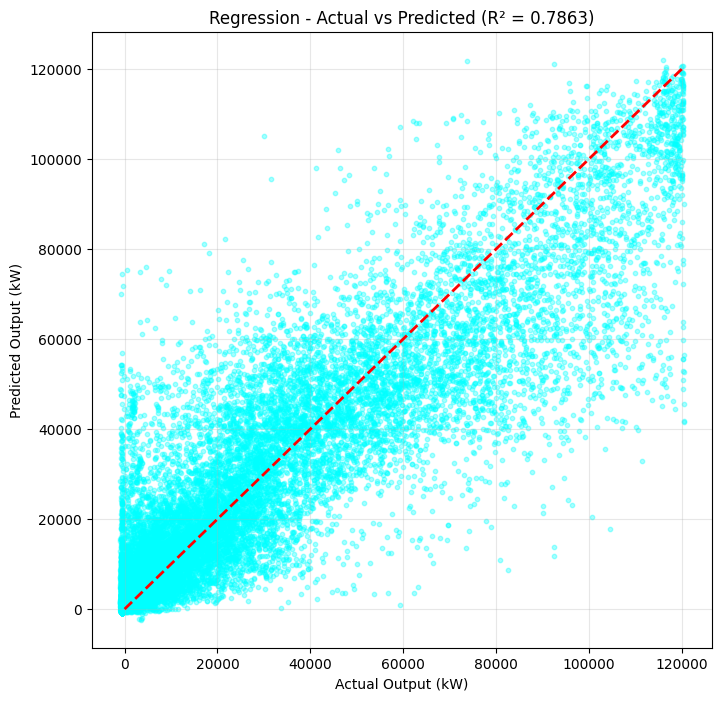

In [11]:
# Cell 6: Regression Plot
plt.figure(figsize=(8, 8))
plt.scatter(y_eval, predictions, alpha=0.35, s=10, color='cyan')
plt.plot([0, y_eval.max()], [0, y_eval.max()], 'r--', lw=2)
plt.xlabel('Actual Output (kW)')
plt.ylabel('Predicted Output (kW)')
plt.title(f'Regression - Actual vs Predicted (R² = {r2:.4f})')
plt.grid(True, alpha=0.3)
plt.show()

Faulty samples: 4073 out of 17668


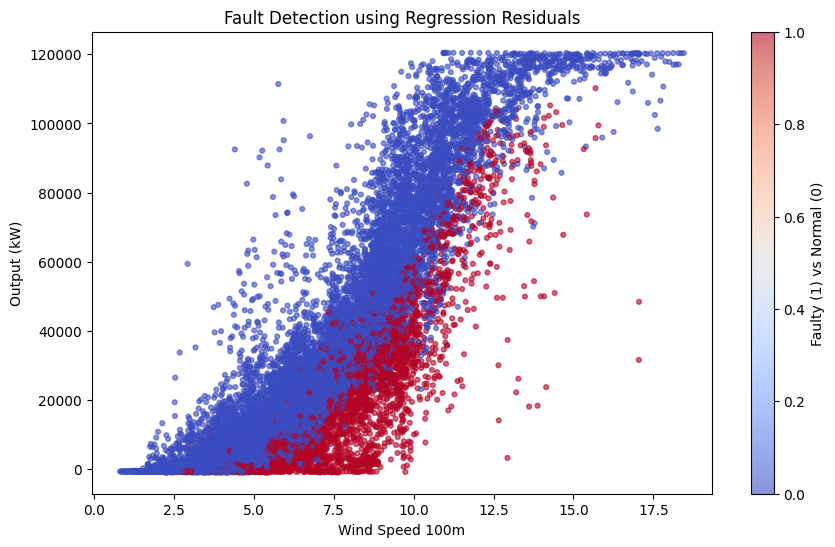

In [12]:
# Cell 7: Generate Faulty/Normal Labels using residuals (Task 5)
residuals = y_eval - predictions
threshold = -7000   # you can tune this value

df_eval['residual'] = residuals
df_eval['faulty'] = (residuals < threshold).astype(int)   # 1 = faulty, 0 = normal

print("Faulty samples:", df_eval['faulty'].sum(), "out of", len(df_eval))

# Visualize (Task 3)
plt.figure(figsize=(10, 6))
plt.scatter(df_eval['wind_speed100M'], df_eval['Output'], 
            c=df_eval['faulty'], cmap='coolwarm', alpha=0.6, s=12)
plt.colorbar(label='Faulty (1) vs Normal (0)')
plt.xlabel('Wind Speed 100m')
plt.ylabel('Output (kW)')
plt.title('Fault Detection using Regression Residuals')
plt.show()

In [13]:
# Cell 8: Save labels for classification
df_eval[['faulty']].to_csv('discrete_eval.csv', index=False)
print("Saved discrete_eval.csv")

Saved discrete_eval.csv


In [14]:
#Classification -Faulty vs Normal

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report


X_train_clf = df_train[feature_cols]
y_train_clf = (df_train['Output']/df_train['available_capacity']<0.65).astype(int)  # Normalize by capacity

X_eval_clf = df_eval[feature_cols]
y_eval_clf = df_eval['faulty']  # Use the generated labels from regression residuals

#Decision Tree Classifier
clf_dt = DecisionTreeClassifier(random_state=42, max_depth=8)
clf_dt.fit(X_train_clf, y_train_clf)
pred_dt = clf_dt.predict(X_eval_clf)

print("Decision Tree Accuracy:", accuracy_score(y_eval_clf, pred_dt))
print(classification_report(y_eval_clf, pred_dt))

Decision Tree Accuracy: 0.2854878877065882
              precision    recall  f1-score   support

           0       0.80      0.10      0.17     13595
           1       0.23      0.92      0.37      4073

    accuracy                           0.29     17668
   macro avg       0.52      0.51      0.27     17668
weighted avg       0.67      0.29      0.22     17668



In [15]:
# Better: Random Forest
clf_rf = RandomForestClassifier(n_estimators=200, random_state=42, max_depth=10)
clf_rf.fit(X_train_clf, y_train_clf)
pred_rf = clf_rf.predict(X_eval_clf)

print("\nRandom Forest Accuracy:", accuracy_score(y_eval_clf, pred_rf))
print(classification_report(y_eval_clf, pred_rf))


Random Forest Accuracy: 0.28214851709304956
              precision    recall  f1-score   support

           0       0.80      0.09      0.16     13595
           1       0.23      0.93      0.37      4073

    accuracy                           0.28     17668
   macro avg       0.52      0.51      0.27     17668
weighted avg       0.67      0.28      0.21     17668

